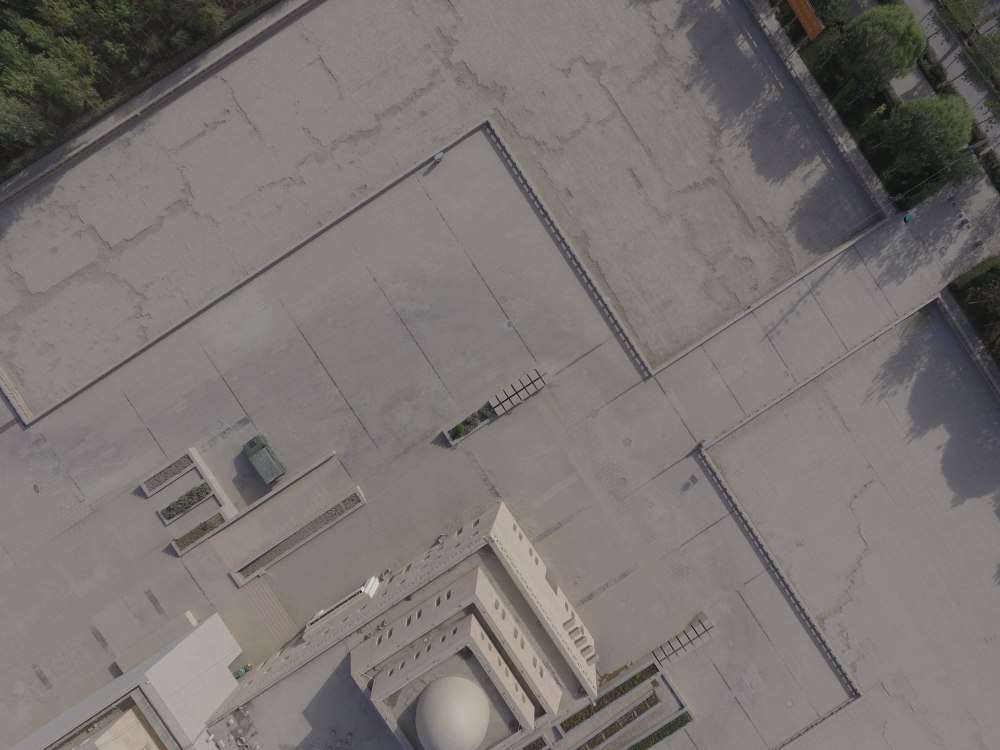

In [1]:
import numpy as np
from PIL import Image, ImageDraw
from pathlib import Path

root = Path(r"C:\Users\t.asmus\Desktop\data\AnyVisLoc\Scene_10\Scene_10")

pp = root / "L10_0119.npz"

file = np.load(pp)


Image.fromarray(file["image"])

In [5]:
file.files

['image',
 'image_relpath',
 'K',
 'dist',
 'uav_downsample',
 'image_size',
 'pose_c2w',
 'pose_w2c',
 'xyz',
 'euler_deg',
 'scene_id',
 'sample_id']

In [4]:
file["image_size"]

array([ 750, 1000], dtype=int32)

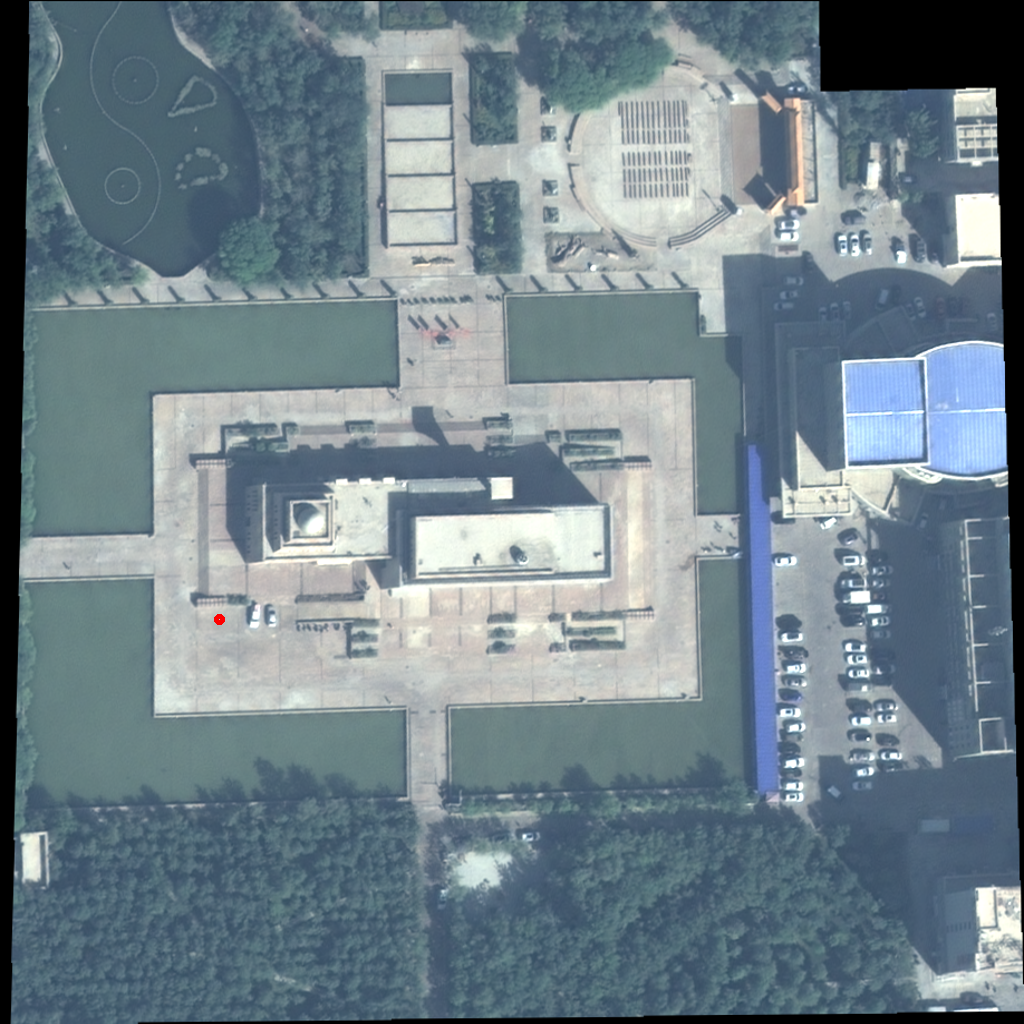

In [2]:
import json 

SIZE = 1024

with open(root / 'L10_reference.json', 'r') as f:
    ref_data = json.load(f)
satellite_info = ref_data['modes']['satellite']
map_resolution = satellite_info['map_resolution']  # [res_x, res_y] в метрах/пиксель
map_origin = satellite_info['map_origin_local']  # [origin_x, origin_y] в метрах

x_meters, y_meters, _ = file["xyz"]

x = int((x_meters - map_origin[0]) / map_resolution[0])
y = int((y_meters - map_origin[1]) / map_resolution[1])

r = 5
img = Image.open(root / "satellite_map.png")

w, h = img.size

scale_x = SIZE / w
scale_y = SIZE / h

x = int(x * scale_x)
y = int(y * scale_y)

img = img.resize((SIZE, SIZE))

draw = ImageDraw.Draw(img)
bounding_box = [x-r, y-r, x+r, y+r]
draw.ellipse(bounding_box, fill='lightblue', outline='red', width=5)

img